# Institutions and development: AJR (2001)
Baseline 2SLS on the 64-country sample used in metricsAI Chapter 13.
Instrument: log settler mortality (`logem4`); endogenous regressor: protection against expropriation (`avexpr`); outcome: log GDP per capita in 1995 (`logpgp95`). No additional controls.

PyFixest estimates IV with HC1 standard errors. Plotly Express draws the first-stage scatter and OLS fit in one call. The final optional styling cell reproduces the website preview.

Sources: [AJR data archive](https://economics.mit.edu/people/faculty/daron-acemoglu/data-archive), [PyFixest IV documentation](https://pyfixest.org/tutorials/formula-syntax.html), [Plotly Express trendlines](https://plotly.com/python/linear-fits/).
Causal interpretation requires the instrument's relevance and exclusion assumptions.


In [ ]:
%pip -q install pyfixest==0.50.1 plotly==6.5.2 statsmodels==0.14.6

In [1]:
import pandas as pd
import pyfixest as pf
import plotly.express as px

df = pd.read_stata("https://raw.githubusercontent.com/quarcs-lab/metricsai/main/data/AED_INSTITUTIONS.DTA")
df = df.dropna(subset=["logpgp95", "avexpr", "logem4"])

In [2]:
iv = pf.feols(
    "logpgp95 ~ 1 | avexpr ~ logem4",
    data=df, vcov="HC1"
)
iv.summary()

###

Estimation:  IV
Dep. var.: logpgp95
sample: None = all
Inference:  HC1
Observations:  64

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| Intercept     |      1.910 |        1.193 |     1.601 |      0.114 | -0.475 |   4.294 |
| avexpr        |      0.944 |        0.179 |     5.278 |      0.000 |  0.587 |   1.302 |
---



In [3]:
import plotly.express as px
fig = px.scatter(
    df, x="logem4", y="avexpr",
    hover_name="shortnam",
    trendline="ols", template="plotly_dark"
)
fig.show()

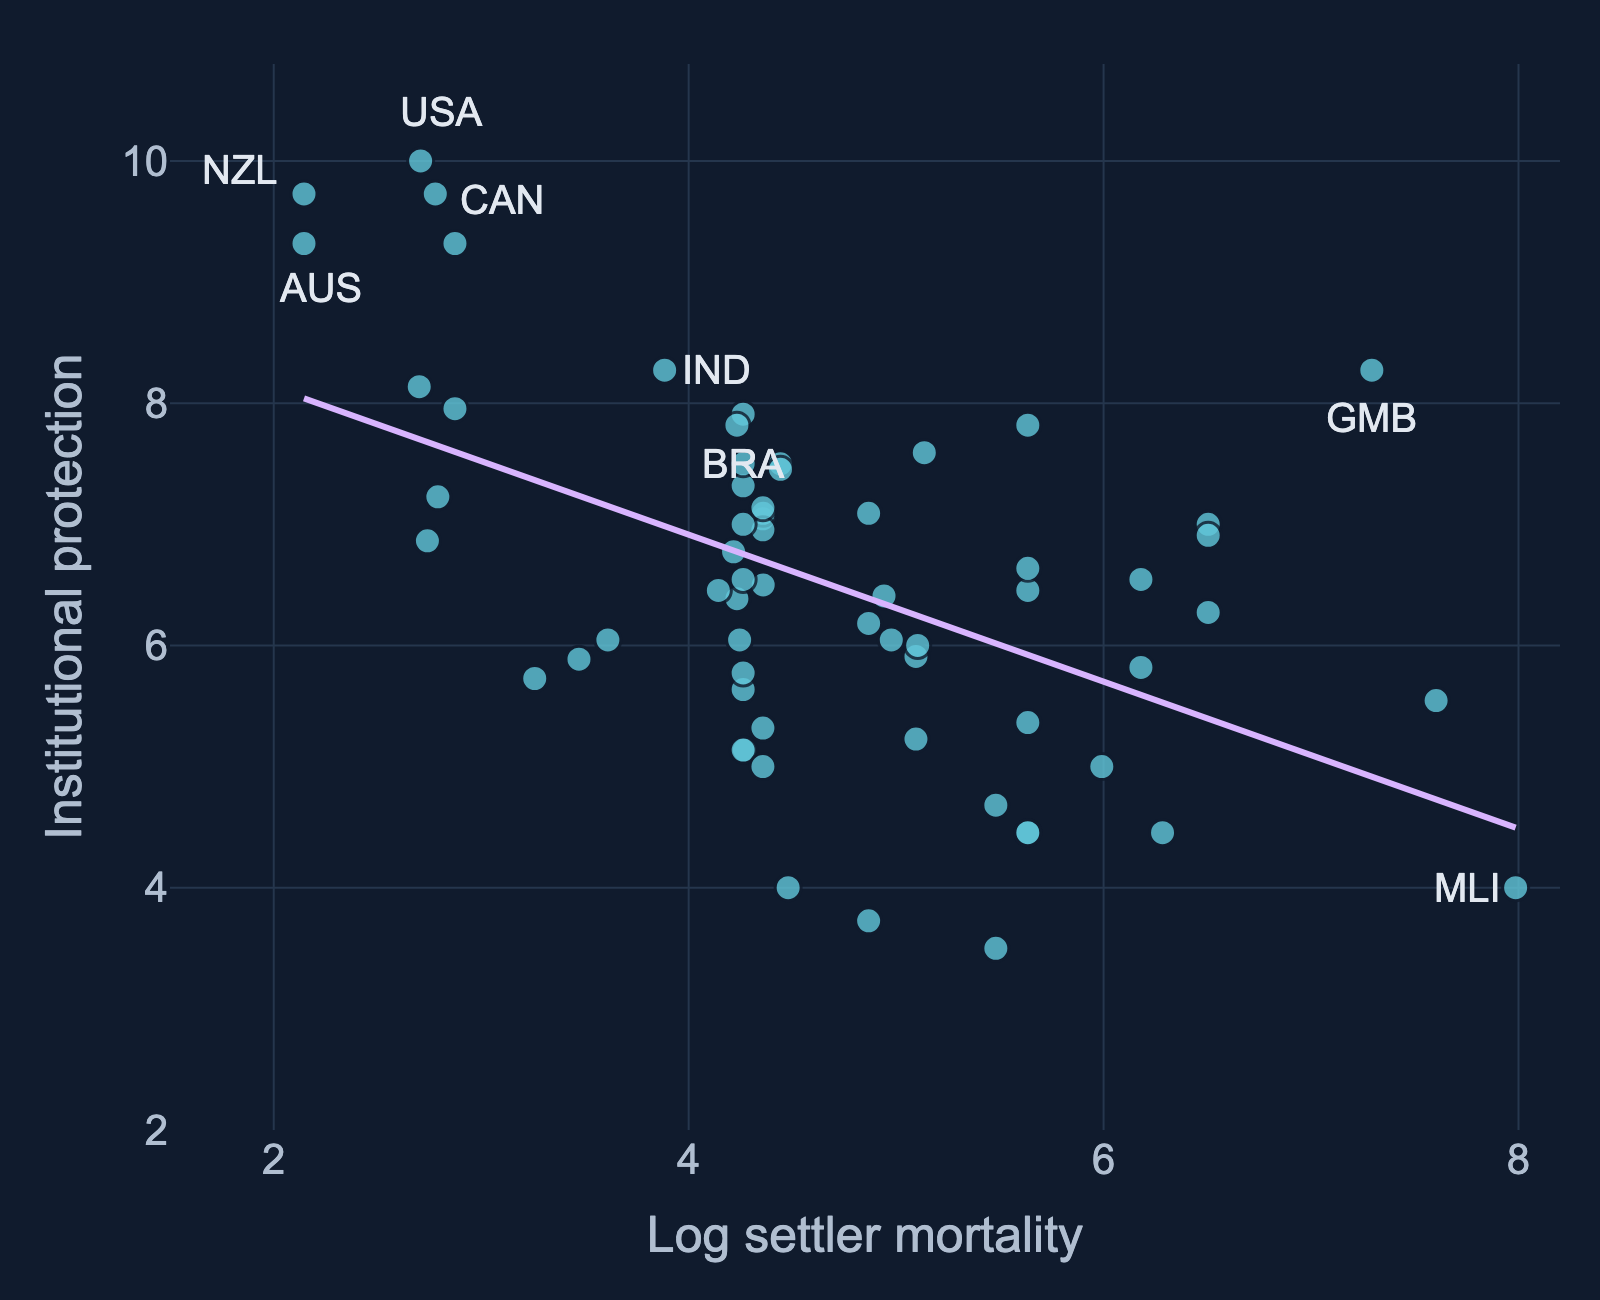

In [4]:
def style_figure(fig, df):
    """Presentation styling, separate from the short teaching example."""
    fig.update_layout(
        width=800, height=650, showlegend=False,
        paper_bgcolor="#101b2d", plot_bgcolor="#101b2d",
        font=dict(family="Arial, sans-serif", size=21, color="#b0bed0"),
        margin=dict(l=85, r=20, t=32, b=85),
        xaxis=dict(title="Log settler mortality", range=[1.5, 8.2], dtick=2,
                   gridcolor="#25364d", zeroline=False, title_standoff=18),
        yaxis=dict(title="Institutional protection", range=[2, 10.8], dtick=2,
                   gridcolor="#25364d", zeroline=False, title_standoff=12),
    )
    fig.update_traces(marker=dict(size=13, color="#62c7da", opacity=.8,
                      line=dict(color="#101b2d", width=1.5)), selector=dict(mode="markers"))
    fig.update_traces(line=dict(color="#d8b4fe", width=3), selector=dict(mode="lines"))
    offsets = {"AUS": (8, -22), "CAN": (33, -3), "USA": (10, 24),
               "NZL": (-32, 12), "BRA": (0, -25), "IND": (26, 0),
               "GMB": (0, -24), "MLI": (-24, 0)}
    for country, (dx, dy) in offsets.items():
        row = df.loc[df.shortnam == country].iloc[0]
        fig.add_annotation(x=float(row.logem4), y=float(row.avexpr), text=country,
                           showarrow=False, xshift=dx, yshift=dy,
                           font=dict(size=20, color="#e2e8f0"))

style_figure(fig, df)
fig.show()